# Capstone Project 1: Body Measurements of Adults (NHANES)

**Working with NumPy Matrices (Multidimensional Data)**

---

## Introduction

This report analyses the body measurements of adult males and females using NumPy matrices. It compares the weight distributions of the two groups, studies the relationships between several body measurements, and evaluates three common body-composition indicators: the body mass index (BMI), the waist-to-height ratio (WHtR) and the waist-to-hip ratio (WHR).

**Data source.** The data are two excerpts from the National Health and Nutrition Examination Survey (NHANES) of the US Centers for Disease Control and Prevention (2017 to March 2020). Both files were downloaded from <https://github.com/gagolews/teaching-data/tree/master/marek>:

* `nhanes_adult_male_bmx_2020.csv`
* `nhanes_adult_female_bmx_2020.csv`

Both files must be saved in the same folder as this notebook.

**Contents**

1. Setup and Data Loading
2. Weight Distributions (Histograms)
3. Weight Comparison (Box Plot)
4. Numerical Summary of Weights
5. Body Mass Index (BMI)
6. Standardised Data (Z-scores)
7. Scatterplot Matrix and Correlations
8. Waist Ratios
9. Waist Ratios Comparison (Box Plot)
10. Advantages and Disadvantages of the Indicators
11. Participants with Extreme BMI Values
12. Conclusions

---

## 1. Setup and Data Loading

Each matrix consists of seven columns. The column index is used throughout the notebook, so it is listed here for reference.

| Index | Measurement |
|:-----:|:------------|
| 0 | Weight (kg) |
| 1 | Standing height (cm) |
| 2 | Upper arm length (cm) |
| 3 | Upper leg length (cm) |
| 4 | Arm circumference (cm) |
| 5 | Hip circumference (cm) |
| 6 | Waist circumference (cm) |

### 1.1 Importing the Libraries

**Purpose.** The required libraries are imported first: NumPy for the matrices, Matplotlib for the plots, and SciPy for the skewness, kurtosis and rank calculations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

**Code explanation.**

* `numpy` provides the matrix type and the mathematical functions.
* `matplotlib.pyplot` provides the plotting functions.
* `scipy.stats` provides ready-made statistical functions.

This cell produces no output.

### 1.2 Reading the Two Files

**Purpose.** The two CSV files are read into NumPy matrices named `male` and `female`.

In [2]:
# read both files
male = np.genfromtxt("nhanes_adult_male_bmx_2020.csv",
                     delimiter=",", comments="#")[1:, :]
female = np.genfromtxt("nhanes_adult_female_bmx_2020.csv",
                       delimiter=",", comments="#")[1:, :]

print("Male shape:", male.shape)
print("Female shape:", female.shape)
print()
print("First male rows:")
print(male[:3])
print("First female rows:")
print(female[:3])

Male shape: (4081, 7)
Female shape: (4221, 7)

First male rows:
[[ 98.8 182.3  42.   40.1  38.2 108.2 120.4]
 [ 74.3 184.2  41.1  41.   30.2  94.5  86.8]
 [103.7 185.3  47.   44.   32.  107.8 109.6]]
First female rows:
[[ 97.1 160.2  34.7  40.8  35.8 126.1 117.9]
 [ 91.1 152.7  33.5  33.   38.5 125.5 103.1]
 [ 73.  161.2  37.4  38.   31.8 106.2  92. ]]


**Code explanation.**

* `np.genfromtxt` reads numeric text files, and `delimiter=","` tells it that the columns are separated by commas.
* `comments="#"` makes it ignore the description lines at the top of each file.
* The column-name row is read as `NaN` (not a number), so `[1:, :]` removes it by keeping all rows except the first one.
* `.shape` returns the number of rows and columns of a matrix.

**Results and discussion.** The male matrix has 4,081 rows and the female matrix has 4,221 rows. Both have seven columns, as expected. The printed rows contain plausible values; for example, the first female participant weighs 97.1 kg and is 160.2 cm tall. The header row was removed correctly, so the matrices contain numerical data only.

---

## 2. Weight Distributions (Histograms)

### 2.1 Choosing the Axis Limits

**Purpose.** Both histograms must use identical x-axis limits. To choose suitable limits, the minimum and maximum weights of the two groups are inspected first.

In [3]:
# weight columns
female_weight = female[:, 0]
male_weight = male[:, 0]

# find ranges
print("Female weight range:", female_weight.min(), "-", female_weight.max())
print("Male weight range:", male_weight.min(), "-", male_weight.max())

Female weight range: 32.6 - 180.9
Male weight range: 36.8 - 204.6


**Code explanation.**

* `female[:, 0]` selects all rows of column 0, which is the weight.
* `.min()` and `.max()` return the smallest and the largest value.

**Results and discussion.** Female weights range from 32.6 kg to 180.9 kg, and male weights range from 36.8 kg to 204.6 kg. The limits of 25 kg and 210 kg include every observation of both groups with a small margin, so they are used for both plots.

### 2.2 Histograms of Female and Male Weights

**Purpose.** Two histograms are drawn on one figure: female weights in the top subfigure and male weights in the bottom subfigure. The identical x-axis limits make a direct visual comparison possible.

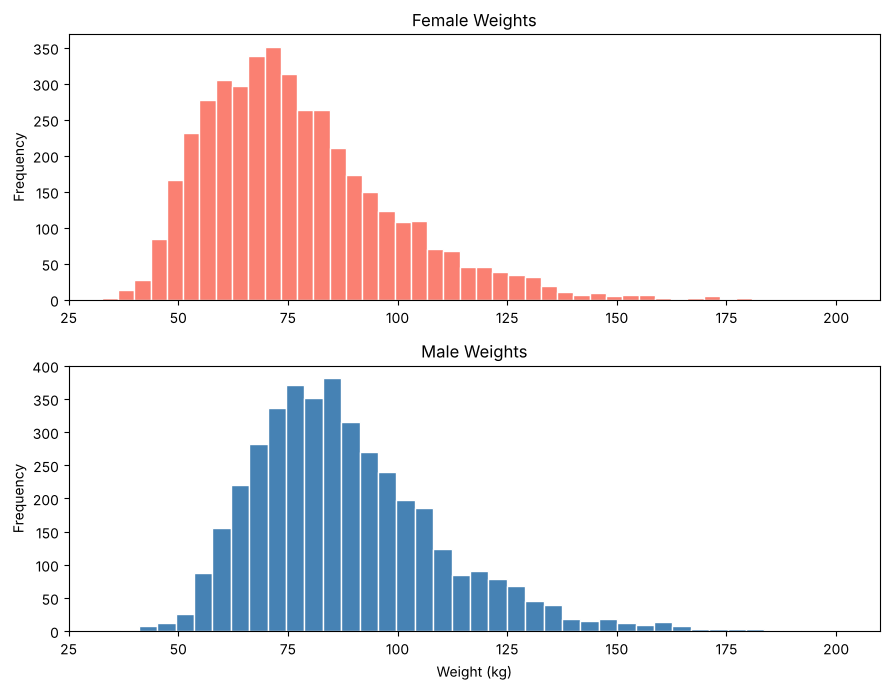

In [4]:
plt.figure(figsize=(9, 7))

# top: females
plt.subplot(2, 1, 1)
plt.hist(female_weight, bins=40, color="salmon", edgecolor="white")
plt.xlim(25, 210)
plt.title("Female Weights")
plt.ylabel("Frequency")

# bottom: males
plt.subplot(2, 1, 2)
plt.hist(male_weight, bins=40, color="steelblue", edgecolor="white")
plt.xlim(25, 210)
plt.title("Male Weights")
plt.xlabel("Weight (kg)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

**Code explanation.**

* `plt.figure(figsize=(9, 7))` sets the size of the whole figure.
* `plt.subplot(2, 1, 1)` creates a grid of 2 rows and 1 column and selects the first (top) plot. `plt.subplot(2, 1, 2)` selects the second (bottom) plot.
* `plt.hist(..., bins=40)` draws the histogram with 40 bars.
* `plt.xlim(25, 210)` sets the same x-axis limits for both subfigures.
* `plt.tight_layout()` prevents the titles and labels from overlapping.

**Results and discussion.** Both distributions have a single peak and a long tail to the right. The female histogram peaks at about 70 to 75 kg, while the male histogram peaks at about 80 to 85 kg, so the male distribution is shifted towards higher weights. The two shapes are otherwise very similar. In both groups a small number of very heavy participants stretches the right tail, reaching about 180 kg for females and about 205 kg for males.

---

## 3. Weight Comparison (Box Plot)

**Purpose.** A box-and-whisker plot places the female and male weights side by side so that their medians, spreads and extreme values can be compared.

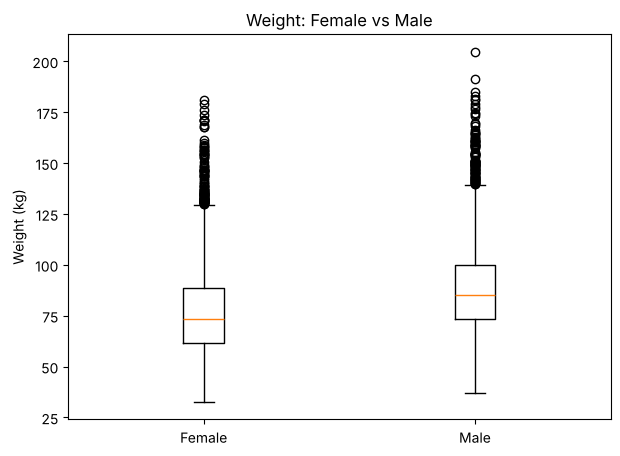

In [5]:
plt.figure(figsize=(7, 5))

plt.boxplot([female_weight, male_weight])
plt.xticks([1, 2], ["Female", "Male"])
plt.ylabel("Weight (kg)")
plt.title("Weight: Female vs Male")

plt.show()

**Code explanation.**

* `plt.boxplot` receives a list of two vectors and draws one box for each of them.
* The box covers the middle 50% of the data (from the first to the third quartile), and the orange line is the median.
* The whiskers show the typical range, and the circles are outliers.
* `plt.xticks` replaces the numbers 1 and 2 with the labels "Female" and "Male".

**Results and discussion.** The median male weight (about 85 kg) is clearly higher than the median female weight (about 74 kg), and the whole male box lies higher. The heights of the two boxes are almost the same, which means that the spread of the middle half of the data is similar in both groups. In both groups the upper whisker is longer than the lower one, and many outliers appear above it but hardly any below. This confirms the right-skewed shapes seen in the histograms. The heaviest outliers belong to the male group.

---

## 4. Numerical Summary of Weights

**Purpose.** The basic numerical aggregates of the weights are computed for both groups: measures of location (mean, median, minimum, maximum), measures of dispersion (standard deviation, variance, interquartile range) and measures of shape (skewness, kurtosis).

In [6]:
def describe(x):
    # collect measures
    return {
        "Mean": np.mean(x),
        "Median": np.median(x),
        "Minimum": np.min(x),
        "Maximum": np.max(x),
        "Std. deviation": np.std(x),
        "Variance": np.var(x),
        "IQR": np.percentile(x, 75) - np.percentile(x, 25),
        "Skewness": stats.skew(x),
        "Kurtosis": stats.kurtosis(x),
    }


female_stats = describe(female_weight)
male_stats = describe(male_weight)

print(f"{'Measure':<16}{'Female':>10}{'Male':>10}")
print("-" * 36)
for name in female_stats:
    print(f"{name:<16}{female_stats[name]:>10.2f}{male_stats[name]:>10.2f}")

Measure             Female      Male
------------------------------------
Mean                 77.40     88.36
Median               73.60     85.00
Minimum              32.60     36.80
Maximum             180.90    204.60
Std. deviation       21.54     21.42
Variance            464.08    458.77
IQR                  27.10     26.50
Skewness              1.03      0.98
Kurtosis              1.40      1.47


**Code explanation.**

* The function `describe` calculates all measures for one vector and returns them in a dictionary (name and value pairs). Using a function avoids repeating the same code for both groups.
* `np.percentile(x, 75) - np.percentile(x, 25)` gives the interquartile range (IQR).
* `stats.skew` measures asymmetry. A positive value means a long right tail.
* `stats.kurtosis` returns the excess kurtosis, which is 0 for a normal distribution. A positive value means heavier tails than normal.
* The `for` loop prints one row of the table for each measure.

**Results and discussion.**

* **Location.** Males are heavier on average. The mean is 88.36 kg for males and 77.40 kg for females (a difference of about 11 kg), and the median is 85.00 kg compared with 73.60 kg.
* **Dispersion.** The absolute dispersion is almost identical: the standard deviations are 21.54 kg (females) and 21.42 kg (males), and the IQRs are 27.10 kg and 26.50 kg. Relative to the mean, females vary slightly more (21.54 / 77.40 is about 0.28, compared with 21.42 / 88.36, which is about 0.24).
* **Shape.** Both distributions are right-skewed (skewness of 1.03 and 0.98), and no distribution is left-skewed. This agrees with the fact that the mean is larger than the median in both groups. The positive kurtosis (1.40 and 1.47) shows heavier tails than a normal distribution, which means that unusually heavy participants occur more often than a bell-shaped curve would predict.
* **Overall.** The male weight distribution looks like the female one shifted by roughly 11 kg, with a very similar spread and shape. The small differences in skewness and kurtosis between the groups are negligible.

---

## 5. Body Mass Index (BMI)

**Purpose.** The body mass index is calculated for every female participant and added to the `female` matrix as the eighth column. It is defined as

$$\text{BMI} = \frac{\text{weight (kg)}}{\text{height (m)}^2}.$$

In [7]:
# compute BMI
height_m = female[:, 1] / 100
bmi = female[:, 0] / height_m ** 2

# add column
female = np.column_stack((female, bmi))

print("New female shape:", female.shape)
print("First BMI values:", np.round(female[:5, 7], 2))

New female shape: (4221, 8)
First BMI values: [37.84 39.07 28.09 24.9  23.18]


**Code explanation.**

* The height is divided by 100 to convert centimetres to metres.
* The calculation works on whole columns at once, so one line computes the BMI of all participants.
* `np.column_stack` joins the old matrix and the new column. The BMI is now at column index 7 (the eighth column).

**Results and discussion.** The female matrix now has eight columns. The first participant has a BMI of 37.84, which is in the obese range (30 or above), the third participant has a BMI of 28.09 (overweight), and the last two values (24.90 and 23.18) are in the normal range (18.5 to 24.9).

---

## 6. Standardised Data (Z-scores)

**Purpose.** A new matrix `zfemale` is created in which every column of the female data is standardised. The z-score of a value $x$ is

$$z = \frac{x - \bar{x}}{s},$$

where $\bar{x}$ is the column mean and $s$ is the column standard deviation. Standardisation removes the units, so columns measured in kilograms, centimetres and BMI units become comparable.

In [8]:
# z-score formula
zfemale = (female - female.mean(axis=0)) / female.std(axis=0)

print("Column means:")
print(np.round(zfemale.mean(axis=0), 2))
print("Column std devs:")
print(np.round(zfemale.std(axis=0), 2))

Column means:
[ 0.  0. -0. -0.  0. -0.  0. -0.]
Column std devs:
[1. 1. 1. 1. 1. 1. 1. 1.]


**Code explanation.**

* `female.mean(axis=0)` and `female.std(axis=0)` calculate one mean and one standard deviation for each column.
* NumPy subtracts and divides each column by its own value automatically (this is called broadcasting).
* The check at the end rounds the column means and standard deviations to two decimals.

**Results and discussion.** After standardisation every column has a mean of 0 and a standard deviation of 1. The value `-0.` is only a tiny negative number caused by rounding errors; it is equal to zero. A z-score of 2 means that a value is two standard deviations above the column mean. The original `female` matrix is unchanged.

---

## 7. Scatterplot Matrix and Correlations

### 7.1 Scatterplot Matrix (Pairplot)

**Purpose.** A scatterplot matrix shows the relationship between every pair of the following standardised variables for females: height, weight, waist circumference, hip circumference and BMI.

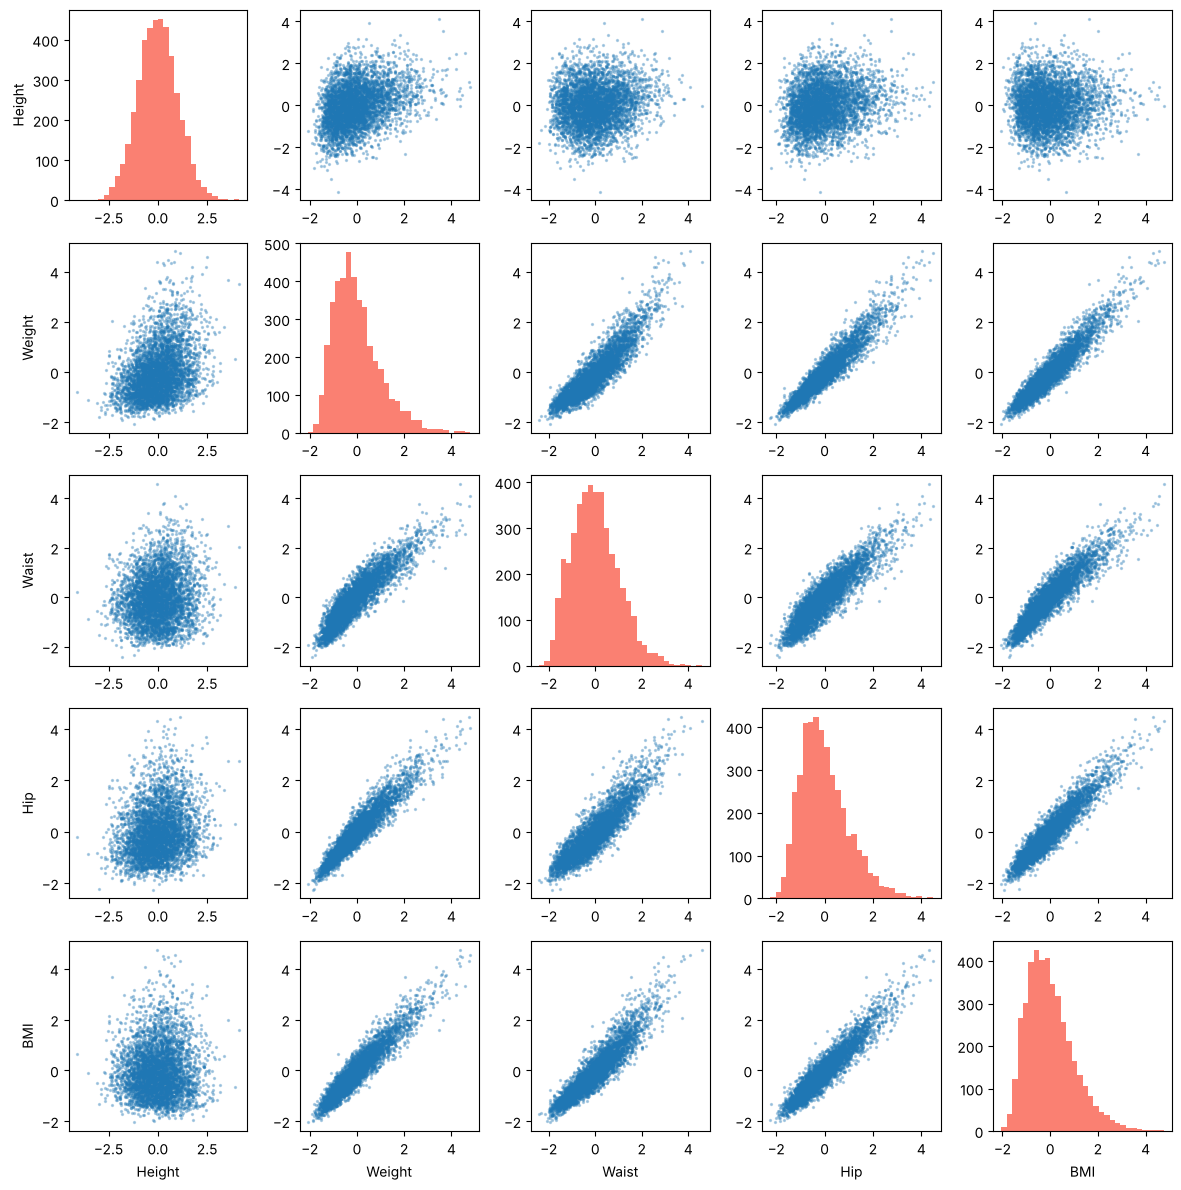

In [9]:
# chosen columns
cols = [1, 0, 6, 5, 7]
names = ["Height", "Weight", "Waist", "Hip", "BMI"]
data = zfemale[:, cols]

fig, axes = plt.subplots(5, 5, figsize=(12, 12))

for i in range(5):
    for j in range(5):
        ax = axes[i, j]
        if i == j:
            ax.hist(data[:, i], bins=30, color="salmon")
        else:
            ax.scatter(data[:, j], data[:, i], s=2, alpha=0.3)
        if i == 4:
            ax.set_xlabel(names[j])
        if j == 0:
            ax.set_ylabel(names[i])

plt.tight_layout()
plt.show()

**Code explanation.**

* `cols` lists the column indices of the selected variables in `zfemale`, and `names` lists their labels.
* `plt.subplots(5, 5)` creates a grid of 25 small plots.
* The two nested `for` loops visit every cell of the grid. On the diagonal (`i == j`) a histogram of the variable is drawn, and elsewhere a scatter plot of two different variables is drawn.
* `s=2` makes the points small, and `alpha=0.3` makes them transparent so that dense areas are visible.

**Results and discussion.** Weight, waist circumference, hip circumference and BMI form narrow, nearly straight bands of points in all of their pairs, which indicates strong positive linear relationships. The plots involving height show wide, round clouds with only a slight upward tendency, so height is only weakly related to the other variables. The histograms on the diagonal show that height is approximately symmetric and bell-shaped, whereas weight, hip circumference and BMI have a clear right tail.

### 7.2 Pearson and Spearman Correlation Coefficients

**Purpose.** Pearson's coefficient measures the strength of a *linear* relationship, whereas Spearman's coefficient measures the strength of a *monotonic* relationship (it is based on ranks). Both are computed for all pairs of the five variables.

In [10]:
def show_matrix(matrix):
    # print table
    print(f"{'':<8}" + "".join(f"{n:>8}" for n in names))
    for i in range(5):
        row = "".join(f"{value:>8.3f}" for value in matrix[i])
        print(f"{names[i]:<8}" + row)


# pearson
pearson = np.corrcoef(data.T)

# spearman
ranks = stats.rankdata(data, axis=0)
spearman = np.corrcoef(ranks.T)

print("Pearson correlation:")
show_matrix(pearson)
print()
print("Spearman correlation:")
show_matrix(spearman)

Pearson correlation:
          Height  Weight   Waist     Hip     BMI
Height     1.000   0.345   0.127   0.203   0.033
Weight     0.345   1.000   0.905   0.947   0.946
Waist      0.127   0.905   1.000   0.897   0.921
Hip        0.203   0.947   0.897   1.000   0.944
BMI        0.033   0.946   0.921   0.944   1.000

Spearman correlation:
          Height  Weight   Waist     Hip     BMI
Height     1.000   0.339   0.109   0.205   0.020
Weight     0.339   1.000   0.900   0.947   0.938
Waist      0.109   0.900   1.000   0.888   0.923
Hip        0.205   0.947   0.888   1.000   0.934
BMI        0.020   0.938   0.923   0.934   1.000


**Code explanation.**

* `np.corrcoef` expects each variable in a row, so the matrix is transposed with `.T`.
* Spearman's coefficient is the Pearson coefficient of the ranks. `stats.rankdata(data, axis=0)` replaces every value by its rank inside its column.
* The function `show_matrix` prints a matrix with the variable names, rounded to three decimals.

**Results and discussion.**

* **Strong relationships.** Weight, waist circumference, hip circumference and BMI are strongly and positively correlated (Pearson between 0.897 and 0.947). The strongest pairs are weight and hip circumference (0.947) and weight and BMI (0.946). The high value for weight and BMI is expected because BMI is calculated from weight.
* **Weak relationships.** Height has a weak positive correlation with weight (0.345), hip circumference (0.203) and waist circumference (0.127). Its correlation with BMI is almost zero (0.033). This shows that BMI does what it was designed for: it removes most of the influence of height from the weight.
* **Pearson and Spearman.** Both coefficients are very close to each other for every pair (for example, 0.947 and 0.947 for weight and hip circumference, and 0.127 and 0.109 for height and waist circumference). Therefore, the relationships are approximately linear, and the outliers do not distort the results.
* **Remark.** A high correlation does not prove causation. Here the high values are mainly explained by the physical fact that a heavier body usually has larger circumferences. Standardisation does not change the correlation coefficients.

---

## 8. Waist Ratios

**Purpose.** Two ratios are added as new columns to both matrices:

* the **waist-to-height ratio (WHtR)** = waist circumference / standing height, and
* the **waist-to-hip ratio (WHR)** = waist circumference / hip circumference.

In [11]:
# male ratios
male_whtr = male[:, 6] / male[:, 1]
male_whr = male[:, 6] / male[:, 5]
male = np.column_stack((male, male_whtr, male_whr))

# female ratios
female_whtr = female[:, 6] / female[:, 1]
female_whr = female[:, 6] / female[:, 5]
female = np.column_stack((female, female_whtr, female_whr))

print("Male shape:", male.shape)
print("Female shape:", female.shape)
print()
print("Mean ratios:")
print(f"{'':<8}{'WHtR':>8}{'WHR':>8}")
print(f"{'Female':<8}{female_whtr.mean():>8.3f}{female_whr.mean():>8.3f}")
print(f"{'Male':<8}{male_whtr.mean():>8.3f}{male_whr.mean():>8.3f}")

Male shape: (4081, 9)
Female shape: (4221, 10)

Mean ratios:
            WHtR     WHR
Female     0.616   0.900
Male       0.586   0.971


**Code explanation.**

* `male[:, 6] / male[:, 1]` divides the waist column (index 6) by the height column (index 1) row by row. Column 5 holds the hip circumference.
* `np.column_stack` appends the two new columns, first the WHtR and then the WHR.
* The male matrix now has 9 columns (WHtR at index 7 and WHR at index 8). The female matrix has 10 columns because the BMI was added earlier (BMI at index 7, WHtR at index 8 and WHR at index 9).
* The separate variables `male_whtr`, `male_whr`, `female_whtr` and `female_whr` are kept so that the later code is easy to read.
* The matrix `zfemale` is not changed, because it was created before these columns were added.

**Results and discussion.** The shapes are (4081, 9) for males and (4221, 10) for females, as expected. On average, females have a higher waist-to-height ratio (0.616 compared with 0.586), while males have a higher waist-to-hip ratio (0.971 compared with 0.900).

---

## 9. Waist Ratios Comparison (Box Plot)

**Purpose.** A box-and-whisker plot with four boxes compares the waist-to-height ratio and the waist-to-hip ratio of females and males.

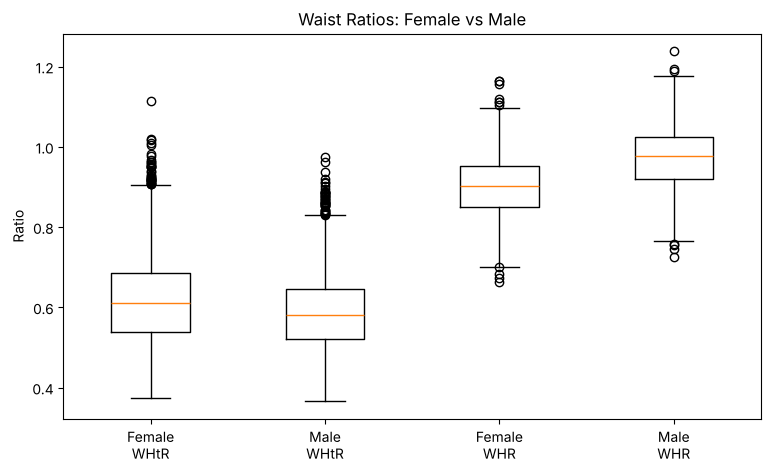

In [12]:
plt.figure(figsize=(9, 5))

plt.boxplot([female_whtr, male_whtr, female_whr, male_whr])
plt.xticks([1, 2, 3, 4],
           ["Female\nWHtR", "Male\nWHtR", "Female\nWHR", "Male\nWHR"])
plt.ylabel("Ratio")
plt.title("Waist Ratios: Female vs Male")

plt.show()

**Code explanation.**

* `plt.boxplot` receives a list of four vectors, so four boxes are drawn in the given order.
* The label text contains `\n`, which starts a new line, so every label has two lines.

**Results and discussion.**

* **Waist-to-height ratio.** The female box lies higher than the male box (the median is about 0.61 for females and 0.58 for males), and it is also taller, so females show a wider spread. Both distributions have many outliers on the upper side, which means that some participants have a very large waist compared with their height. Even the lower quartile of each group (about 0.52 to 0.54) is above 0.5, a value often quoted as a guideline for a healthy waist.
* **Waist-to-hip ratio.** The pattern is reversed: the male box lies clearly higher (the median is about 0.98 for males and 0.90 for females). The boxes have a similar height, and the outliers appear on both sides, so these distributions are more symmetric than those of the weights and the WHtR.
* **Interpretation.** The sex difference changes direction depending on the indicator. Women are smaller in height, which raises their WHtR, whereas men usually carry less fat around the hips relative to the waist, which raises their WHR. Therefore, the ratios of males and females should be judged against sex-specific reference values.

---

## 10. Advantages and Disadvantages of the Indicators

The table below summarises the strengths and weaknesses of the three indicators.

| Indicator | Advantages | Disadvantages |
|:----------|:-----------|:--------------|
| **BMI** | Very simple and cheap, because only weight and height are needed. Both values are easy to measure accurately. Standard categories (underweight, normal, overweight, obese) are widely known, which makes it a useful screening tool for large populations. | It cannot distinguish fat from muscle, so a muscular athlete may be classified as overweight. It does not show where the fat is stored. It ignores age, sex and body frame, and its category limits are somewhat arbitrary. It can be less reliable for very short or very tall people. |
| **Waist-to-height ratio (WHtR)** | It reflects abdominal fat, which is strongly linked with heart and metabolic diseases. It takes height into account. A single simple guideline (0.5) is often used for both sexes and for different ages. It is easy to explain: the waist should be less than half of the height. | The waist measurement depends on the technique (position of the tape, breathing, time after a meal), so measurement errors are possible. It cannot separate dangerous deep abdominal fat from fat under the skin. It is less established in official guidelines than BMI. |
| **Waist-to-hip ratio (WHR)** | It describes the fat distribution ("apple" or "pear" shape) and not only the body size. It is a recognised predictor of cardiovascular risk. | It needs two measurements, so the errors of both are combined. The hip measurement includes muscle and bone, so it is hard to interpret. Both measurements can fall during weight loss, and the ratio may then change very little. Different reference values are required for males and females, and two people with a different health risk can have the same ratio. |

In practice, the indicators complement each other. BMI describes the overall body size, while the two ratios describe how fat is distributed. A reliable assessment should combine them (and, where possible, other measurements) and should not rely on a single number.

---

## 11. Participants with Extreme BMI Values

**Purpose.** The standardised body measurements of the five females with the lowest BMI and the five females with the highest BMI are printed, and the patterns of these extreme cases are examined.

In [13]:
# sort by BMI
order = np.argsort(female[:, 7])
lowest = order[:5]
highest = order[-5:]

np.set_printoptions(precision=2, suppress=True, linewidth=120)

print("Columns: weight, height, arm length, leg length,")
print("arm circ., hip circ., waist circ., BMI")
print()
print("Lowest BMI (z-scores):")
print(zfemale[lowest])
print()
print("Highest BMI (z-scores):")
print(zfemale[highest])
print()
print("Lowest BMI values:", female[lowest, 7])
print("Highest BMI values:", female[highest, 7])

Columns: weight, height, arm length, leg length,
arm circ., hip circ., waist circ., BMI

Lowest BMI (z-scores):
[[-2.08 -1.22 -1.55 -1.17 -2.19 -2.04 -1.94 -2.05]
 [-1.88 -0.19 -1.72  0.39 -2.44 -1.85 -2.06 -1.99]
 [-1.54  1.81  0.63  0.57 -2.27 -1.68 -1.71 -1.97]
 [-1.84 -0.26 -0.23  0.51 -2.3  -2.25 -1.86 -1.94]
 [-1.61  0.89 -0.1   0.48 -2.21 -1.83 -1.71 -1.89]]

Highest BMI (z-scores):
[[ 4.25  0.29  1.86 -0.98  2.37  4.1   3.82  4.4 ]
 [ 4.46  0.5   1.69 -1.14  3.35  3.98  2.9   4.46]
 [ 4.35  0.28  2.84  1.94  4.37  3.92  3.75  4.51]
 [ 4.8   0.89  2.12  1.82  3.78  4.02  4.08  4.54]
 [ 4.36 -0.03 -0.06 -0.17  2.78  4.32  4.57  4.76]]

Lowest BMI values: [14.2  14.63 14.82 15.04 15.42]
Highest BMI values: [64.2  64.71 65.12 65.33 67.04]


**Code explanation.**

* `np.argsort` does not sort the values themselves; it returns the row numbers in the order that would sort them. Here, the rows are ordered by BMI (column 7) from the smallest to the largest.
* `order[:5]` takes the first five row numbers (lowest BMI), and `order[-5:]` takes the last five (highest BMI). The highest values are therefore printed in ascending order, and the last row is the person with the maximum BMI.
* `zfemale[lowest]` selects these rows from the standardised matrix.
* `np.set_printoptions` limits the output to two decimals. The real BMI values are printed as well to make the interpretation easier.

**Results and discussion.**

* **Lowest BMI.** The five lowest BMI values lie between 14.20 and 15.42, which is well below 18.5 (underweight). All five are even below 16, the limit commonly used for severe thinness. In standardised terms, the BMI is about 2 standard deviations below the mean. Weight, hip circumference, waist circumference and especially arm circumference (z-scores of about -2.2 to -2.4) are all clearly below average. Their heights differ strongly (z-scores from -1.22 to 1.81), so the low BMI is not a matter of body height; for example, one participant is much taller than average and still very slim.
* **Highest BMI.** The five highest values lie between 64.20 and 67.04, far into the range of severe obesity (above 40). The z-scores of BMI and weight are about 4.4 to 4.8, and hip and waist circumferences are also very high (z-scores of about 2.9 to 4.6). The heights of these participants are close to the average (z-scores between -0.03 and 0.89), so the high BMI comes from the weight and not from a small body height.
* **Asymmetry.** The highest values are about 4.5 standard deviations above the mean, but the lowest values are only about 2 standard deviations below it. This confirms the strong right skew of the data: extremely high values exist, whereas extremely low values are limited by the human body. In a normal distribution, z-scores above 4 would be very rare.
* **Other measurements.** The upper arm length and upper leg length vary from person to person in both groups, which shows that these skeleton-based measurements have no clear connection with BMI.

---

## 12. Conclusions

* **Weight.** Males are about 11 kg heavier than females on average. The spread and the shape of both distributions are very similar: both are right-skewed with heavy tails.
* **Relationships.** Weight, waist circumference, hip circumference and BMI are strongly correlated for females, while height is only weakly related to them. The Pearson and Spearman coefficients agree closely.
* **Indicators.** Females show a higher waist-to-height ratio, and males show a higher waist-to-hip ratio. For this reason, sex-specific interpretation is needed.
* **Extreme cases.** The highest BMI values are much further from the mean than the lowest ones, which confirms the right-skewed distribution of body mass in the population.
* **Limitations.** The analysis is descriptive. It shows associations and not causes, and the indicators discussed here should be used together with other health information.